# 06. Hyperparameter tuning (LightGBM)

**Question:** how much does tuning add on top of the hand-picked settings (5-fold AUC 0.7868)?

**Plan**
1. Rebuild the same dataset as notebook 04 (application + bureau + previous + installments).
2. Search the settings with Optuna, scoring each trial with 3-fold CV.
3. Re-score the best settings on a *different* split. The best trial's CV score is optimistic, because we picked it for being the highest on those very folds. A fresh split gives an honest number.

In [1]:
# Imports and setup shared by the whole notebook
import sys, json
# make the project's src/ package importable from the notebooks folder
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb
import optuna
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.features import clean, add_features

# keep the output readable: only warnings, not one line per trial
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Build the modelling table
Rebuild the same feature table as notebook 04: cleaned application data plus the bureau, previous-application and installment aggregates. Every later step reuses this one table, so the tuning compares like with like.

In [2]:
# Load the raw data and build the feature table (application + 3 aggregate tables)
df = pd.read_csv("../data/raw/HC_application_train.csv")
# target: 1 = payment difficulties
y = df["TARGET"]
# clean placeholders, then add ratio and external-score features
X = add_features(clean(df.drop(columns="TARGET")))
# attach the pre-computed aggregates, matched on applicant id
for name in ["bureau", "previous", "installments"]:
    X = X.join(pd.read_pickle(f"../data/processed/{name}.pkl"), on="SK_ID_CURR")
X = X.drop(columns="SK_ID_CURR")
# text columns become LightGBM native categories
for c in X.select_dtypes(include=["object", "string"]):
    X[c] = X[c].astype("category")
print(X.shape, f"positives: {y.mean():.2%}")

(307511, 518) positives: 8.07%


**Insight:** 307,511 applicants with 518 features, and 8.07% positives, so the classes are imbalanced and AUC is the right metric.

## What we tune and why
| Setting | What it does | Risk if wrong |
|---|---|---|
| `learning_rate` + number of trees | Step size per tree. Smaller steps need more trees. | Too many trees overfit; we use **early stopping** to pick the count |
| `num_leaves`, `max_depth` | How complex each tree can be | Too large overfits |
| `min_child_samples` | Minimum rows in a leaf | Too small fits noise |
| `colsample_bytree`, `subsample` | Random share of columns / rows per tree | Adds diversity; too small underfits |
| `reg_alpha`, `reg_lambda` | Penalty on large leaf values | Too large underfits |

We search with a fast learning rate (0.1) so each trial is cheap, then lower it (0.03) for the final model.

The next cell runs the Optuna search over these settings: 30 trials, each scored by 3-fold cross-validation, starting from roughly the old hand-picked settings.

In [3]:
# Optuna search: 30 trials of LightGBM settings, each scored by 3-fold CV AUC
dtrain = lgb.Dataset(X, label=y, free_raw_data=False)
# fixed folds (seed 42) so every trial is scored on the same splits
cv_search = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=42).split(X, y))

# one trial: sample settings, return the cross-validated AUC
def objective(trial):
    params = {
        "objective": "binary", "metric": "auc", "verbosity": -1, "seed": 42,
        "learning_rate": 0.1,
        "num_leaves": trial.suggest_int("num_leaves", 16, 128),
        "max_depth": trial.suggest_categorical("max_depth", [-1, 4, 6, 8, 10]),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 300),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 0.6),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    # early stopping picks the number of trees for each setting
    res = lgb.cv(params, dtrain, num_boost_round=1000, folds=cv_search,
                 callbacks=[lgb.early_stopping(50, verbose=False)])
    # remember how many trees were used
    trial.set_user_attr("best_rounds", len(res["valid auc-mean"]))
    return res["valid auc-mean"][-1]

# TPE sampler with a fixed seed for reproducibility
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
# trial 0 = the old settings, so the search has a baseline to beat
study.enqueue_trial({"num_leaves": 31, "max_depth": -1, "min_child_samples": 20, "colsample_bytree": 0.3,
                     "subsample": 1.0, "reg_alpha": 0.001, "reg_lambda": 0.001})   # start from roughly the old settings
# kept small to stay cheap; more trials would likely add little (see plot)
N_TRIALS = 30
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
print("best 3-fold AUC:", round(study.best_value, 4))
print(study.best_params)

best 3-fold AUC: 0.7875
{'num_leaves': 25, 'max_depth': 6, 'min_child_samples': 168, 'colsample_bytree': 0.5122140776749146, 'subsample': 0.8094554807322794, 'reg_alpha': 9.544173371791882, 'reg_lambda': 0.05671881712775827}


**Insight:** the best 3-fold AUC is 0.7875, with num_leaves 25, max_depth 6, min_child_samples 168 and a strong L1 penalty (reg_alpha 9.5). This number is optimistic because it is the maximum over 30 trials on the same folds; the fresh split below gives the honest figure.

## Search results

The table shows the five best trials, to check whether the winner stands out or sits on a plateau of similar settings.

In [4]:
# Collect all trials into a table and show the five best
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
# strip the params_ / user_attrs_ prefixes from the column names
trials = trials.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
# highest AUC first
trials.sort_values("value", ascending=False).head(5).round(4)

,number,value,colsample_bytree,max_depth,min_child_samples,num_leaves,reg_alpha,reg_lambda,subsample,best_rounds
13,13,0.7875,0.5122,6,168,25,9.5442,0.0567,0.8095,314
25,25,0.7874,0.4417,6,201,22,3.9690,0.0043,0.8288,272
27,27,0.7872,0.4460,6,195,22,6.7886,0.0039,0.7953,350
24,24,0.7869,0.5497,6,199,18,7.3229,0.0371,0.7469,352
22,22,0.7868,0.5052,6,151,17,2.7675,0.0238,0.7918,369


**Insight:** the five best trials lie between 0.7868 and 0.7875, a spread of 0.0007, far below the 0.003 to 0.004 fold-to-fold noise. They agree on max_depth 6 and on a fairly large min_child_samples (151 to 201), so the search found a plateau of similar settings rather than one sharp optimum.

The left plot shows each trial's score and the best score so far; the right plot shows which settings the score was most sensitive to.

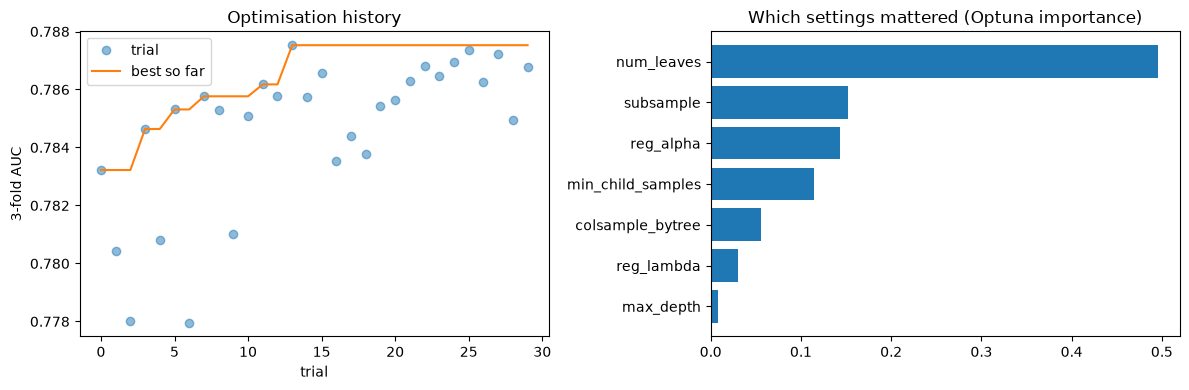

In [5]:
# Plot the search history and Optuna's importance of each setting
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(trials["number"], trials["value"], "o", alpha=0.5, label="trial")
# running maximum = best score found so far
ax[0].plot(trials["number"], trials["value"].cummax(), "-", label="best so far")
ax[0].set_xlabel("trial"); ax[0].set_ylabel("3-fold AUC"); ax[0].legend(); ax[0].set_title("Optimisation history")

# how much of the AUC variation each setting explains
imp = optuna.importance.get_param_importances(study)
# reversed so the most important setting is at the top
ax[1].barh(list(imp)[::-1], list(imp.values())[::-1])
ax[1].set_title("Which settings mattered (Optuna importance)")
plt.tight_layout(); plt.show()

**Insight:** the best-so-far line climbs from about 0.783 to 0.7875 by trial 13 and does not improve over the remaining 16 trials, so 30 trials were enough here. num_leaves is by far the most influential setting (importance about 0.5), while max_depth matters least.

## Honest evaluation on a fresh split
Different folds (seed 7) from the search (seed 42). Each variant uses early stopping on the same folds, so the comparison is fair. Early stopping on the evaluation fold is slightly generous, but it is applied equally to every row.

| Row | Settings |
|---|---|
| original | `n_estimators=300, learning_rate=0.05, colsample_bytree=0.3` (as in notebooks 04/05) |
| old settings + early stopping | same, but number of trees chosen by early stopping at learning rate 0.03 |
| tuned | best Optuna settings, learning rate 0.03, early stopping |

The cell below scores the three variants on 5 folds and reports mean AUC, fold standard deviation and the number of trees used.

In [6]:
# Score the three variants on a fresh 5-fold split (seed 7) with the same protocol
# different seed from the search, so the tuned settings are not scored on the folds they were picked on
folds_final = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=7).split(X, y))

# train on each fold; return per-fold AUC and the mean number of trees
def score(params, rounds=None):
    aucs, used = [], []
    for tr, va in folds_final:
        # validation set shares the training set's bin definitions via reference
        dt = lgb.Dataset(X.iloc[tr], y.iloc[tr]); dv = lgb.Dataset(X.iloc[va], y.iloc[va], reference=dt)
        # fixed tree count for the original row, early stopping for the others
        cb = [] if rounds else [lgb.early_stopping(100, verbose=False)]
        m = lgb.train(params, dt, num_boost_round=rounds or 3000, valid_sets=[dv], callbacks=cb)
        # predict with the best (or fixed) number of trees
        aucs.append(roc_auc_score(y.iloc[va], m.predict(X.iloc[va], num_iteration=rounds or m.best_iteration)))
        used.append(rounds or m.best_iteration)
    return np.array(aucs), int(np.mean(used))

# settings shared by every variant
common = {"objective": "binary", "metric": "auc", "verbosity": -1, "seed": 42}
# original hand-picked settings (300 trees)
old = {**common, "learning_rate": 0.05, "colsample_bytree": 0.3}
# same settings, lower learning rate, trees chosen by early stopping
old_es = {**common, "learning_rate": 0.03, "colsample_bytree": 0.3}
# tuned settings from the Optuna search
best = {**common, "learning_rate": 0.03, "subsample_freq": 1, **study.best_params}

# train each variant and collect its scores
rows = []
for label, p, r in [("original (300 trees)", old, 300), ("old settings + early stopping", old_es, None), ("tuned", best, None)]:
    a, n = score(p, r)
    rows.append({"variant": label, "AUC mean": a.mean(), "AUC std": a.std(), "trees": n})
    print(rows[-1], flush=True)

final = pd.DataFrame(rows)
# improvement over the original row
final["vs original"] = final["AUC mean"] - final.loc[0, "AUC mean"]
final.round(4)

{'variant': 'original (300 trees)', 'AUC mean': np.float64(0.7868925876289423), 'AUC std': np.float64(0.0031784382026540645), 'trees': 300}


{'variant': 'old settings + early stopping', 'AUC mean': np.float64(0.7893035218461716), 'AUC std': np.float64(0.0026909454209575047), 'trees': 1030}


{'variant': 'tuned', 'AUC mean': np.float64(0.7913784795164341), 'AUC std': np.float64(0.0032905538673235284), 'trees': 1164}


,variant,AUC mean,AUC std,trees,vs original
0,original (300 trees),0.7869,0.0032,300,0.0000
1,old settings + early stopping,0.7893,0.0027,1030,0.0024
2,tuned,0.7914,0.0033,1164,0.0045


**Insight:** mean AUC rises from 0.7869 (300 trees) to 0.7893 (old settings with early stopping, 1,030 trees) to 0.7914 (tuned, 1,164 trees). The first step alone is +0.0024, so most of the gain comes from more trees at a lower learning rate, not from the search itself.

Finally compare the gain from tuning with the fold-to-fold spread, and save the chosen settings to `models/best_params.json` so notebooks 07 and 09 use the same model.

In [7]:
# Check whether tuning beat the old early-stopped settings by more than the noise, then save the parameters
# tuned minus old settings, both early-stopped
gain = final.loc[2, "AUC mean"] - final.loc[1, "AUC mean"]
# typical fold standard deviation of the two rows
spread = final.loc[[1, 2], "AUC std"].mean()
print(f"tuned vs old settings (both early-stopped): {gain:+.4f}  (fold std about {spread:.4f})")
# a gain below the fold spread cannot be told apart from noise
print("Verdict:", "gain is larger than the fold spread" if gain > spread else "gain is within the fold spread, i.e. close to noise")

# create the output folder if missing
Path("../models").mkdir(exist_ok=True)
# also store the learning rate and the tree count found by early stopping
saved = {**study.best_params, "learning_rate": 0.03, "subsample_freq": 1, "n_estimators": int(final.loc[2, "trees"])}
json.dump(saved, open("../models/best_params.json", "w"), indent=2)
saved

tuned vs old settings (both early-stopped): +0.0021  (fold std about 0.0030)
Verdict: gain is within the fold spread, i.e. close to noise


{'num_leaves': 25,
 'max_depth': 6,
 'min_child_samples': 168,
 'colsample_bytree': 0.5122140776749146,
 'subsample': 0.8094554807322794,
 'reg_alpha': 9.544173371791882,
 'reg_lambda': 0.05671881712775827,
 'learning_rate': 0.03,
 'subsample_freq': 1,
 'n_estimators': 1164}

**Insight:** tuned beats the old early-stopped settings by +0.0021 with a fold std of about 0.0030, so the gain is within noise. We keep the tuned parameters because they are no worse, and with only one repeated split this should not be read as proof that they are better.